# Cidade Alfa 156+ · Fase 4 — Exploração e Preparação de Dados

**Grupo Data_Drivens · PBL Data Science · FIAP**

Este notebook mostra, passo a passo, como preparamos e exploramos **1,5 milhão de chamados reais**
do SP156 (dados abertos da Prefeitura de São Paulo, licença CC0, jan–set/2026) para responder à
pergunta do projeto: **os chamados estão sendo resolvidos dentro do prazo (SLA)?**

| Pilar da Fase 4 | Onde está |
| --- | --- |
| 1. Qualidade e higienização | Passos 3 e 4 |
| 2. Engenharia de atributos | Passo 5 |
| 3. Análise exploratória (EDA) | Passo 6 |

> A Cidade Alfa é fictícia e usa São Paulo como referência real. Os **prazos (SLA)** de cada
> serviço são definidos pelo catálogo do app Cidade Alfa 156+; o SP156 não publica prazos oficiais.

**Como rodar no Colab:** `Ambiente de execução → Executar tudo`. O Passo 1 baixa as planilhas
do portal (~125 MB, alguns minutos). Leva cerca de 5 a 10 minutos no total.

In [1]:
# Leitor rápido de Excel (o Colab não traz por padrão)
import importlib.util, subprocess, sys
if importlib.util.find_spec('python_calamine') is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'python-calamine'], check=True)

In [2]:
import os, re, unicodedata, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))

# Paleta validada para daltonismo (azul = dentro do prazo, laranja = atraso)
COR = {'serie': '#2a78d6', 'texto': '#0b0b0b', 'texto2': '#52514e', 'mudo': '#898781',
       'grade': '#e1e0d9', 'eixo': '#c3c2b7', 'fundo': '#fcfcfb'}
FAIXAS = [('Atendido em 24h', '#1c5cab'), ('No prazo', '#6da7ec'),
          ('Atraso leve', '#eb6834'), ('Atraso crítico', '#a8400f')]
plt.rcParams.update({
    'figure.facecolor': COR['fundo'], 'axes.facecolor': COR['fundo'], 'font.size': 11,
    'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': COR['grade'], 'axes.axisbelow': True, 'legend.frameon': False,
    'axes.edgecolor': COR['eixo'], 'xtick.color': COR['texto2'], 'axes.labelcolor': COR['texto2'],
})
br = lambda t: t.translate(str.maketrans(',.', '.,'))          # 52,142.5 -> 52.142,5
MILHAR = matplotlib.ticker.FuncFormatter(lambda v, _: br(f'{v:,.0f}'))

## Passo 1 — Obter os dados

Três planilhas trimestrais do portal [dados.prefeitura.sp.gov.br](https://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156).
Usamos o **XLSX** (as datas vêm tipadas; o CSV do portal usa mês/dia/ano).

Se já tiver os arquivos, coloque-os numa pasta e aponte `DADOS_SP156` para ela (no Colab: faça
upload para `/content/dados_sp156` ou monte o Google Drive).

In [3]:
PORTAL = 'https://dados.prefeitura.sp.gov.br/dataset/0aecfa2b-aa3a-40d4-8183-0d4351b7fd0a/resource'
PLANILHAS = {
    'arquivo-final-1-trim-26.xlsx': '71859131-9dd1-458c-ae95-1092799c7d95',
    'arquivo-final-2-trim-26.xlsx': '3ae65d07-d3e2-417a-becc-659a51cdce57',
    'arquivo-final-3-trim-26.xlsx': '4288a1e6-d495-42d6-be1e-6169f729cced',
}
PASTA = Path(os.environ.get('DADOS_SP156', 'dados_sp156'))
PASTA.mkdir(parents=True, exist_ok=True)

for nome, recurso in PLANILHAS.items():
    destino = PASTA / nome
    if destino.exists() and destino.stat().st_size > 1_000_000:
        print(f'ok (já existe)  {nome}  {destino.stat().st_size/1e6:,.1f} MB')
        continue
    print(f'baixando        {nome} …', end=' ', flush=True)
    urllib.request.urlretrieve(f'{PORTAL}/{recurso}/download/{nome}', destino)
    print(f'{destino.stat().st_size/1e6:,.1f} MB')

ok (já existe)  arquivo-final-1-trim-26.xlsx  49.3 MB
ok (já existe)  arquivo-final-2-trim-26.xlsx  40.7 MB
ok (já existe)  arquivo-final-3-trim-26.xlsx  34.8 MB


## Definições de negócio (vindas do app)

- **Serviços do app** e o texto correspondente no SP156.
- **Prazo (SLA)** de cada serviço, em dias corridos.
- **Data de corte** de cada planilha: o status "Aberto" vale para a data em que o arquivo foi
  extraído (última finalização registrada nele), não para hoje.

In [4]:
SERVICOS = {  # código no app: nome, secretaria, prazo em dias, urgência (1 a 3) para o score
    'via':      {'nome': 'Buraco na via',                'secretaria': 'Obras',          'sla': 7,  'urgencia': 3},
    'residuos': {'nome': 'Entulho e descarte irregular', 'secretaria': 'Limpeza Urbana', 'sla': 5,  'urgencia': 2},
    'bueiro':   {'nome': 'Limpeza de bueiro',            'secretaria': 'Limpeza Urbana', 'sla': 7,  'urgencia': 2},
    'calcada':  {'nome': 'Guias e sarjetas',             'secretaria': 'Obras',          'sla': 20, 'urgencia': 1},
    'arvore':   {'nome': 'Poda ou remoção de árvore',    'secretaria': 'Meio Ambiente',  'sla': 30, 'urgencia': 3},
    'veiculo':  {'nome': 'Veículo abandonado',           'secretaria': 'Mobilidade',     'sla': 30, 'urgencia': 1},
}
MAPA = [  # início do texto do serviço no SP156 (normalizado) -> código no app
    ('tapa-buraco', 'via'),
    ('entulho e grandes objetos em via publica', 'residuos'),
    ('denunciar descarte irregular de entulho', 'residuos'),
    ('arvore - solicitar avaliacao em calcadas e pracas', 'arvore'),
    ('solicitar remocao de veiculo/carcaca abandonado', 'veiculo'),
    ('solicitar limpeza de bueiros', 'bueiro'),
    ('guias, sarjetas e sarjetoes - solicitar manutencao', 'calcada'),
]
CORTES = {'2026-1': '2026-08-06', '2026-2': '2026-08-06', '2026-3': '2026-10-08'}
SUBPREFEITURAS = {
    'aricanduva-formosa-carrao': 'Aricanduva-Formosa-Carrão', 'butanta': 'Butantã', 'campo limpo': 'Campo Limpo',
    'capela do socorro': 'Capela do Socorro', 'casa verde-limao-cachoeirinha': 'Casa Verde-Limão-Cachoeirinha',
    'casa verde-cachoeirinha': 'Casa Verde-Limão-Cachoeirinha', 'cidade ademar': 'Cidade Ademar',
    'cidade tiradentes': 'Cidade Tiradentes', 'ermelino matarazzo': 'Ermelino Matarazzo',
    'freguesia-brasilandia': 'Freguesia-Brasilândia', 'guaianases': 'Guaianases', 'ipiranga': 'Ipiranga',
    'itaim paulista': 'Itaim Paulista', 'itaquera': 'Itaquera', 'jabaquara': 'Jabaquara',
    'jacana-tremembe': 'Jaçanã-Tremembé', 'lapa': 'Lapa', 'm boi mirim': "M'Boi Mirim", 'mooca': 'Mooca',
    'parelheiros': 'Parelheiros', 'penha': 'Penha', 'perus': 'Perus-Anhanguera', 'perus-anhanguera': 'Perus-Anhanguera',
    'pinheiros': 'Pinheiros', 'pirituba-jaragua': 'Pirituba-Jaraguá', 'santana-tucuruvi': 'Santana-Tucuruvi',
    'santo amaro': 'Santo Amaro', 'sao mateus': 'São Mateus', 'sao miguel': 'São Miguel', 'sapopemba': 'Sapopemba',
    'se': 'Sé', 'vila maria-vila guilherme': 'Vila Maria-Vila Guilherme', 'vila mariana': 'Vila Mariana',
    'vila prudente': 'Vila Prudente',
}
LIMITES_SP = {'lat': (-24.1, -23.3), 'lon': (-47.0, -46.3)}   # caixa do município
STATUS = {'finalizada': 'finalizada', 'finalizado': 'finalizada', 'aberto': 'aberta', 'aberta': 'aberta',
          'em andamento': 'em_andamento', 'cancelada': 'cancelada', 'cancelado': 'cancelada', 'em aprovacao': 'em_aprovacao'}

def normalizar(s):
    """minúsculas, sem acento, sem espaços extras (para comparar textos da fonte)."""
    return (s.astype('string').str.replace('–', '-').str.replace('—', '-')
            .str.normalize('NFKD').str.encode('ascii', 'ignore').str.decode('ascii')
            .str.lower().str.strip().str.replace(r'\s+', ' ', regex=True))

def servico_app(texto):
    t = unicodedata.normalize('NFKD', str(texto).replace('–', '-')).encode('ascii', 'ignore').decode().lower()
    t = ' '.join(t.split())
    return next((cod for prefixo, cod in MAPA if t.startswith(prefixo)), None)

def numero(s):
    return pd.to_numeric(s.astype('string').str.replace(',', '.'), errors='coerce').astype('float64')

## Passo 2 — Carregar (camada Raw)

Lemos a aba **Solicitações** de cada planilha e padronizamos os nomes das colunas.

In [5]:
COLUNAS = {
    'data de abertura': 'data_abertura', 'data de finalizacao': 'data_finalizacao',
    'meio de comunicacao': 'canal', 'tema': 'tema', 'assunto': 'assunto', 'servico': 'servico_sp156',
    'status': 'status_original', 'orgao': 'orgao', 'logradouro': 'logradouro', 'numero': 'numero',
    'cep': 'cep', 'latitude': 'latitude', 'longitude': 'longitude',
    'prefeitura operacional': 'prefeitura_operacional', 'distrito': 'distrito',
}
partes = []
for nome in PLANILHAS:
    df = pd.read_excel(PASTA / nome, sheet_name=0, engine='calamine', dtype=object)
    df.columns = normalizar(pd.Series(df.columns)).tolist()
    df = df.rename(columns=COLUNAS)[list(COLUNAS.values())]
    df['arquivo'] = nome.replace('.xlsx', '')
    partes.append(df)
    print(f'{nome}: {len(df):,} linhas'.replace(',', '.'))
bruto = pd.concat(partes, ignore_index=True)
del partes
print(f'\nTotal: {len(bruto):,} chamados · {bruto.shape[1]} colunas'.replace(',', '.'))
bruto.head()

arquivo-final-1-trim-26.xlsx: 577.989 linhas


arquivo-final-2-trim-26.xlsx: 463.686 linhas


arquivo-final-3-trim-26.xlsx: 484.232 linhas



Total: 1.525.907 chamados · 16 colunas


,data_abertura,data_finalizacao,canal,tema,assunto,servico_sp156,status_original,orgao,logradouro,numero,cep,latitude,longitude,prefeitura_operacional,distrito,arquivo
0,2026-01-01 00:00:00,2026-01-01 00:00:00,CRM,Cidadania e assistência social,População ou pessoa em situação de rua,Baixas Temperaturas - Solicitar abordagem soci...,Finalizada,SMADS-SEAS República regional,Avenida Paulista,542,01310000,-23.5677346,-46.6483768,SE,BELA VISTA,arquivo-final-1-trim-26
1,2026-01-01 00:00:00,2026-01-06 00:00:00,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Mboi Mirim,NaN,NaN,NaN,NaN,NaN,NaN,NaN,arquivo-final-1-trim-26
2,2026-01-01 00:00:00,2026-01-21 00:00:00,CRM,Rua e bairro,Drenagem de água de chuva,"Solicitar limpeza de bueiros, boca de lobo e p...",Finalizada,INTEGRAÇÃO-AMLURB-FLIP,Rua Guilherme Espíndola Pequito,30,04937050,-23.6886772,-46.7642512,M BOI MIRIM,JARDIM ANGELA,arquivo-final-1-trim-26
3,2026-01-01 00:00:00,2026-01-06 00:00:00,PORTAL,Animais,Castração,Castrar Cães e Gatos Gratuitamente,Finalizada,SMS-DVZ-COSAP-Mboi Mirim,NaN,NaN,NaN,NaN,NaN,NaN,NaN,arquivo-final-1-trim-26
4,2026-01-01 00:00:00,2026-02-25 00:00:00,PORTAL,Rua e bairro,Terrenos e imóveis,Denunciar falta de limpeza de terrenos e imóve...,Finalizada,INTEGRACAO-SGF,Rua Nazaré Rezek Farah,291,04367050,-23.652082,-46.6678808,JABAQUARA,JABAQUARA,arquivo-final-1-trim-26


## Passo 3 — Diagnóstico de qualidade (antes de limpar)

Antes de mexer em qualquer dado, medimos os problemas: campos vazios, coordenadas inválidas,
datas incoerentes, status desconhecidos e duplicidades.

In [6]:
vazio = lambda c: bruto[c].isna() | (bruto[c].astype('string').str.strip() == '')
nulos = pd.DataFrame({'coluna': list(COLUNAS.values())})
nulos['vazios'] = [int(vazio(c).sum()) for c in nulos['coluna']]
nulos['pct'] = 100 * nulos['vazios'] / len(bruto)

lat, lon = numero(bruto['latitude']), numero(bruto['longitude'])
tem_coord = lat.notna() & lon.notna()
dentro = lat.between(*LIMITES_SP['lat']) & lon.between(*LIMITES_SP['lon'])
abertura = pd.to_datetime(bruto['data_abertura'], errors='coerce')
final = pd.to_datetime(bruto['data_finalizacao'], errors='coerce')
status = normalizar(bruto['status_original']).map(STATUS).fillna('outro')

diagnostico = pd.Series({
    'Sem data de abertura': abertura.isna().sum(),
    'Finalização antes da abertura': (final < abertura).sum(),
    'Finalizada sem data de finalização': ((status == 'finalizada') & final.isna()).sum(),
    'Status vazio ou desconhecido': (status == 'outro').sum(),
    'Sem coordenadas': (~tem_coord).sum(),
    'Coordenadas fora do município': (tem_coord & ~dentro).sum(),
    'Linhas idênticas em todas as colunas': bruto.duplicated(subset=list(COLUNAS.values())).sum(),
}, name='linhas').astype(int).to_frame()
diagnostico['% da base'] = 100 * diagnostico['linhas'] / len(bruto)
display(diagnostico)
display(status.value_counts().rename('chamados').to_frame())

,linhas,% da base
Sem data de abertura,0,"0,00"
Finalização antes da abertura,0,"0,00"
Finalizada sem data de finalização,4596,"0,30"
Status vazio ou desconhecido,0,"0,00"
Sem coordenadas,564810,"37,01"
Coordenadas fora do município,2355,"0,15"
Linhas idênticas em todas as colunas,481162,"31,53"


,chamados
status_original,
finalizada,1313488
aberta,192000
em_andamento,12478
cancelada,7940
em_aprovacao,1


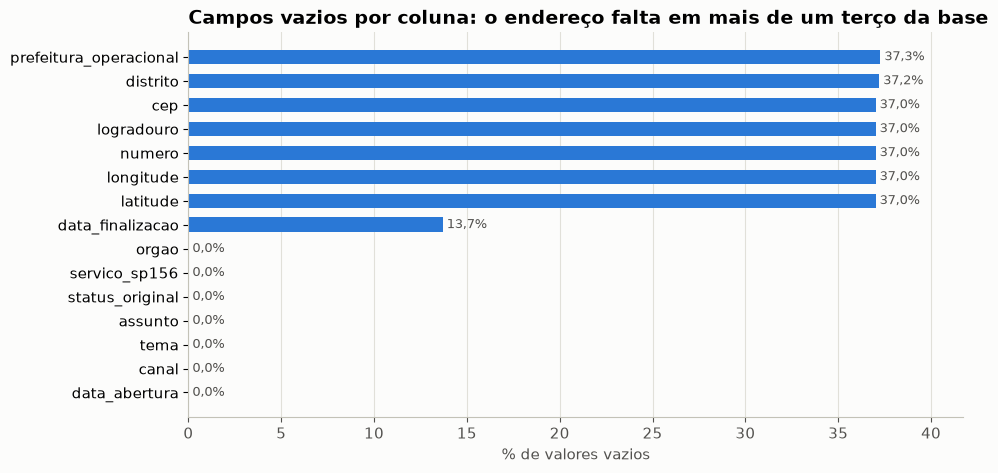

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
n = nulos.sort_values('pct')
ax.barh(n['coluna'], n['pct'], color=COR['serie'], height=.6)
for i, v in enumerate(n['pct']):
    ax.text(v, i, ' ' + br(f'{v:.1f}%'), va='center', fontsize=9.5, color=COR['texto2'])
ax.set_xlabel('% de valores vazios'); ax.grid(axis='y', visible=False); ax.margins(x=.12)
ax.set_title('Campos vazios por coluna: o endereço falta em mais de um terço da base')
plt.show()

**Leitura do diagnóstico**

- **37% sem coordenada:** são serviços sem local físico (cadastro de animais, ouvidoria, finanças).
  Ficam na base, mas fora das análises espaciais.
- **31% de linhas idênticas:** a base aberta **não traz o número de protocolo**. Dois pedidos
  diferentes, no mesmo dia e sem endereço, ficam idênticos. Por isso **não deduplicamos às cegas**.
- Nomes de subprefeitura sem acento e **dois nomes trocados no meio do ano**
  (Perus → Perus-Anhanguera; Casa Verde-Cachoeirinha → Casa Verde-Limão-Cachoeirinha).

## Passo 4 — Higienização (camada Prata)

Princípio: **nenhum chamado é apagado sem motivo**. Os problemas viram *flags* e cada métrica decide
o que excluir. Toda decisão fica registrada.

In [8]:
log = []
registrar = lambda etapa, n, decisao: log.append({'etapa': etapa, 'linhas': int(n), 'decisão': decisao})
limpo = bruto.copy()

limpo['data_abertura'] = pd.to_datetime(limpo['data_abertura'], errors='coerce')
limpo['data_finalizacao'] = pd.to_datetime(limpo['data_finalizacao'], errors='coerce')
limpo['status'] = normalizar(limpo['status_original']).map(STATUS).fillna('outro')

limpo['flag_finalizacao_sem_data'] = (limpo['status'] == 'finalizada') & limpo['data_finalizacao'].isna()
registrar('Finalizada sem data de finalização', limpo['flag_finalizacao_sem_data'].sum(), 'mantida; fora do tempo de atendimento')

lat, lon = numero(limpo['latitude']), numero(limpo['longitude'])
valida = lat.between(*LIMITES_SP['lat']) & lon.between(*LIMITES_SP['lon'])
limpo['latitude'], limpo['longitude'] = lat.where(valida), lon.where(valida)
limpo['flag_coord_valida'] = valida.astype(int)
registrar('Coordenada ausente ou fora do município', (~valida).sum(), 'coordenada anulada; registro mantido')

num = limpo['numero'].astype('string').str.strip()
num_ok = num.str.fullmatch(r'\d+', na=False) & pd.to_numeric(num, errors='coerce').fillna(0).between(1, 25000)
registrar('Número predial inválido (> 25.000 ou não numérico)', (num.notna() & (num != '') & ~num_ok).sum(), 'número anulado')
limpo['numero'] = num.where(num_ok)

pref = normalizar(limpo['prefeitura_operacional'])
registrar('Subprefeitura com nome antigo', pref.isin(['perus', 'casa verde-cachoeirinha']).sum(), 'unificada no nome atual')
registrar('Prefeitura operacional que não é território', (pref.notna() & ~pref.isin(list(SUBPREFEITURAS))).sum(),
          'anulada (órgão ou "não encontrada")')
limpo['prefeitura_operacional'] = pref.map(SUBPREFEITURAS)

# Duplicata provável: mesmo serviço, mesmo dia e mesmo ponto (coordenada + endereço)
chave = ['servico_sp156', 'data_abertura', 'latitude', 'longitude', 'logradouro', 'numero']
limpo['flag_duplicata_provavel'] = (limpo['flag_coord_valida'] == 1) & limpo.duplicated(subset=chave, keep='first')
tamanho = limpo.groupby(chave, dropna=False)['servico_sp156'].transform('size')
limpo['repeticoes_mesmo_ponto'] = (tamanho - 1).where(limpo['flag_coord_valida'] == 1, 0).astype(int)
registrar('Duplicata provável (mesmo serviço, dia e ponto)', limpo['flag_duplicata_provavel'].sum(),
          'mantida com flag; fora das métricas de SLA')

pd.DataFrame(log)

,etapa,linhas,decisão
0,Finalizada sem data de finalização,4596,mantida; fora do tempo de atendimento
1,Coordenada ausente ou fora do município,567165,coordenada anulada; registro mantido
2,Número predial inválido (> 25.000 ou não numér...,912,número anulado
3,Subprefeitura com nome antigo,5280,unificada no nome atual
4,Prefeitura operacional que não é território,4266,"anulada (órgão ou ""não encontrada"")"
5,"Duplicata provável (mesmo serviço, dia e ponto)",110053,mantida com flag; fora das métricas de SLA


## Passo 5 — Engenharia de atributos (camada Ouro)

Ficamos com os 6 serviços do app (finalizados, abertos e em andamento; sem canceladas e sem
duplicatas prováveis) e criamos os atributos de SLA:

| Atributo | Definição |
| --- | --- |
| `data_limite_sla` | abertura + prazo do serviço |
| `data_referencia` | conclusão (finalizados) ou data de corte da planilha (abertos) |
| `tempo_atendimento_dias` | conclusão − abertura |
| **`estouro_sla_dias`** | referência − limite (positivo = dias de atraso) |
| **`flag_cumpriu_sla`** | 1 = no prazo · 0 = atrasou · vazio = aberto ainda no prazo |
| **`faixa_atendimento`** | Atendido em 24h · No prazo · Atraso leve (até o dobro do prazo) · Atraso crítico |
| `flag_outlier_tempo` | acima de Q3 + 1,5·IQR do serviço (regra de Tukey) |
| `flag_backlog_critico` | aberto há mais de 100 dias na data de corte |
| calendário | dia da semana, dia do mês, semana do mês, fim de semana |

In [9]:
limpo['servico_app'] = limpo['servico_sp156'].map({u: servico_app(u) for u in limpo['servico_sp156'].dropna().unique()})
trimestre = limpo['data_abertura'].dt.year.astype(str) + '-' + limpo['data_abertura'].dt.quarter.astype(str)
limpo['data_corte'] = pd.to_datetime(trimestre.map(CORTES))
limpo['dia_semana'] = limpo['data_abertura'].dt.day_of_week
limpo['dia_mes'] = limpo['data_abertura'].dt.day
limpo['semana_do_mes'] = (limpo['dia_mes'] - 1) // 7 + 1
limpo['flag_fim_de_semana'] = (limpo['dia_semana'] >= 5).astype(int)

sla = limpo[limpo['servico_app'].notna() & limpo['status'].isin(['finalizada', 'aberta', 'em_andamento'])
            & ~limpo['flag_duplicata_provavel'] & ~limpo['flag_finalizacao_sem_data']].copy()
sla['servico'] = sla['servico_app'].map(lambda k: SERVICOS[k]['nome'])
sla['sla_dias'] = sla['servico_app'].map(lambda k: SERVICOS[k]['sla'])
sla['data_limite_sla'] = sla['data_abertura'] + pd.to_timedelta(sla['sla_dias'], unit='D')
sla['flag_finalizada'] = (sla['status'] == 'finalizada').astype(int)
sla['data_referencia'] = sla['data_finalizacao'].where(sla['flag_finalizada'] == 1, sla['data_corte'])
sla['tempo_atendimento_dias'] = (sla['data_finalizacao'] - sla['data_abertura']).dt.days.where(sla['flag_finalizada'] == 1)
sla['idade_na_corte_dias'] = (sla['data_corte'] - sla['data_abertura']).dt.days.where(sla['flag_finalizada'] == 0)
sla['estouro_sla_dias'] = (sla['data_referencia'] - sla['data_limite_sla']).dt.days
sla['flag_cumpriu_sla'] = np.select(
    [sla['flag_finalizada'].eq(1) & sla['estouro_sla_dias'].le(0), sla['estouro_sla_dias'].gt(0)], [1, 0], np.nan)

def faixa(tempo, prazo, finalizada, estouro):
    if not finalizada:
        return 'Em aberto (atrasado)' if estouro > 0 else 'Em aberto (no prazo)'
    if tempo <= 1: return 'Atendido em 24h'
    if estouro <= 0: return 'No prazo'
    return 'Atraso leve' if estouro <= prazo else 'Atraso crítico'
sla['faixa_atendimento'] = [faixa(t, p, f == 1, e) for t, p, f, e in
                            zip(sla['tempo_atendimento_dias'], sla['sla_dias'], sla['flag_finalizada'], sla['estouro_sla_dias'])]

def limite_tukey(s):
    q1, q3 = s.quantile([.25, .75]); return q3 + 1.5 * (q3 - q1)
sla['flag_outlier_tempo'] = (sla['tempo_atendimento_dias'] > sla.groupby('servico_app')['tempo_atendimento_dias'].transform(limite_tukey)).astype(int)
p99 = sla.groupby('servico_app')['tempo_atendimento_dias'].transform(lambda s: s.quantile(.99))
sla['tempo_atendimento_wins_dias'] = sla['tempo_atendimento_dias'].clip(upper=p99)
sla['flag_backlog_critico'] = (sla['idade_na_corte_dias'] > 100).astype(int)

print(f'Base de SLA: {len(sla):,} chamados'.replace(',', '.'))
sla[['servico', 'data_abertura', 'data_limite_sla', 'data_referencia', 'tempo_atendimento_dias',
     'estouro_sla_dias', 'flag_cumpriu_sla', 'faixa_atendimento']].sample(8, random_state=156)

Base de SLA: 317.482 chamados


,servico,data_abertura,data_limite_sla,data_referencia,tempo_atendimento_dias,estouro_sla_dias,flag_cumpriu_sla,faixa_atendimento
1418480,Limpeza de bueiro,2026-09-11,2026-09-18,2026-09-11,"0,00",-7,"1,00",Atendido em 24h
574012,Buraco na via,2026-03-30,2026-04-06,2026-08-06,NaN,122,"0,00",Em aberto (atrasado)
200408,Poda ou remoção de árvore,2026-01-29,2026-02-28,2026-04-28,"89,00",59,"0,00",Atraso crítico
1071083,Entulho e descarte irregular,2026-07-06,2026-07-11,2026-07-25,"19,00",14,"0,00",Atraso crítico
744142,Entulho e descarte irregular,2026-04-30,2026-05-05,2026-05-02,"2,00",-3,"1,00",No prazo
1497142,Buraco na via,2026-09-25,2026-10-02,2026-09-28,"3,00",-4,"1,00",No prazo
115067,Guias e sarjetas,2026-01-16,2026-02-05,2026-04-16,"90,00",70,"0,00",Atraso crítico
610207,Poda ou remoção de árvore,2026-04-06,2026-05-06,2026-06-30,"85,00",55,"0,00",Atraso crítico


### Score de prioridade comunitária (RN-03)

A base aberta **não tem apoios** de cidadãos. Como aproximação honesta, usamos as **reclamações
repetidas do mesmo problema** (mesmo serviço, dia e ponto): cada repetição é, na prática, mais
alguém apoiando o chamado.

$$\text{score} = \text{urgência} \times \left(1 + \log_2(1 + \text{apoios})\right)$$

- **Urgência** (1 a 3) pelo risco à segurança: árvore e buraco = 3; bueiro e entulho = 2; guias e veículo = 1.
- O $\log_2$ amortece: 0 apoios → ×1 · 1 → ×2 · 3 → ×3 · 7 → ×4.
- Quando o app registrar apoios reais, basta trocar `apoios_proxy` pela contagem de apoios.

In [10]:
sla['urgencia_base'] = sla['servico_app'].map(lambda k: SERVICOS[k]['urgencia'])
sla['apoios_proxy'] = sla['repeticoes_mesmo_ponto']
sla['score_prioridade_comunidade'] = (sla['urgencia_base'] * (1 + np.log2(1 + sla['apoios_proxy']))).round(2)

print(f"{100 * (sla['apoios_proxy'] > 0).mean():.1f}% dos chamados têm ao menos uma repetição".replace('.', ','))
sla.nlargest(8, 'score_prioridade_comunidade')[['servico', 'data_abertura', 'logradouro', 'prefeitura_operacional',
                                               'apoios_proxy', 'score_prioridade_comunidade']]

4,7% dos chamados têm ao menos uma repetição


,servico,data_abertura,logradouro,prefeitura_operacional,apoios_proxy,score_prioridade_comunidade
1048492,Buraco na via,2026-07-02,Rua Anoriaçu,Jaçanã-Tremembé,52,"20,18"
434585,Buraco na via,2026-03-27,Rua Anoriaçu,Jaçanã-Tremembé,38,"18,86"
592382,Buraco na via,2026-04-03,Rua Anoriaçu,Jaçanã-Tremembé,34,"18,39"
1380530,Buraco na via,2026-09-03,Rua Anoriaçu,Jaçanã-Tremembé,32,"18,13"
435317,Buraco na via,2026-03-27,Rua Anoriaçu,Jaçanã-Tremembé,30,"17,86"
1426149,Buraco na via,2026-09-13,Rua Lopes da Costa,Jaçanã-Tremembé,29,"17,72"
639461,Buraco na via,2026-04-11,Rua Anoriaçu,Jaçanã-Tremembé,28,"17,57"
1426167,Buraco na via,2026-09-13,Rua Anoriaçu,Jaçanã-Tremembé,28,"17,57"


> ⚠️ O topo do ranking tem dezenas de repetições no mesmo ponto e dia — provável **coordenada padrão de
> geocodificação** (centroide), não dezenas de pessoas no mesmo lugar. Isso precisa ser investigado antes de
> usar o score para priorizar atendimento.

## Passo 6 — Análise exploratória (EDA)

### 6.1 Tempo de atendimento por serviço
Média, mediana, desvio-padrão e percentis dos chamados finalizados, comparados ao prazo.

In [11]:
fin = sla[sla['flag_finalizada'] == 1]
g = fin.groupby('servico')['tempo_atendimento_dias']
tempo = pd.DataFrame({
    'finalizados': g.size(), 'média': g.mean(), 'média wins. p99': fin.groupby('servico')['tempo_atendimento_wins_dias'].mean(),
    'mediana': g.median(), 'desvio': g.std(), 'p90': g.quantile(.9), 'p99': g.quantile(.99),
    'outliers': fin.groupby('servico')['flag_outlier_tempo'].sum(),
    'prazo': fin.groupby('servico')['sla_dias'].first(),
    '% no prazo': 100 * fin.groupby('servico')['flag_cumpriu_sla'].mean(),
})
abertos = sla[sla['flag_finalizada'] == 0].groupby('servico').size()
tempo['% abertos na corte'] = 100 * abertos / (tempo['finalizados'] + abertos)
tempo = tempo.sort_values('mediana')
tempo

,finalizados,média,média wins. p99,mediana,desvio,p90,p99,outliers,prazo,% no prazo,% abertos na corte
servico,,,,,,,,,,,
Entulho e descarte irregular,112355,"1,97","1,89","1,00","4,07","4,00","20,00",5742,5,"94,89","2,39"
Limpeza de bueiro,16159,"4,90","4,84","1,00","8,18","18,00","30,00",2338,7,"80,25","8,52"
Buraco na via,56625,"14,75","14,41","7,00","20,34","41,00","89,00",4653,7,"50,68","27,56"
Poda ou remoção de árvore,42709,"27,45","27,20","17,00","29,59","68,00","137,00",2220,30,"68,81","20,72"
Guias e sarjetas,12005,"34,76","34,61","21,00","37,64","83,00","172,00",579,20,"49,71","48,42"
Veículo abandonado,7556,"46,37","46,23","36,00","37,27","99,00","173,00",348,30,"41,45","74,29"


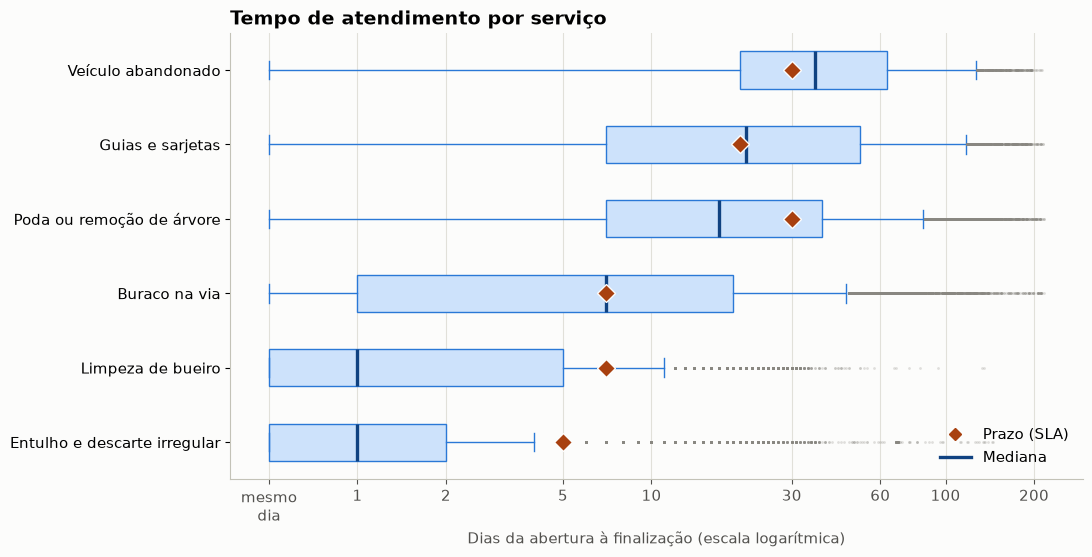

In [12]:
ordem = tempo.index.tolist()
kw = {'orientation': 'horizontal'} if tuple(map(int, matplotlib.__version__.split('.')[:2])) >= (3, 10) else {'vert': False}
fig, ax = plt.subplots(figsize=(11, 5.8))
ax.boxplot([fin.loc[fin['servico'] == s, 'tempo_atendimento_dias'].clip(lower=.5) for s in ordem], widths=.5,
           patch_artist=True, boxprops={'facecolor': '#cde2fb', 'edgecolor': COR['serie']},
           medianprops={'color': '#104281', 'linewidth': 2.4}, whiskerprops={'color': COR['serie']},
           capprops={'color': COR['serie']},
           flierprops={'marker': 'o', 'markersize': 2, 'markerfacecolor': COR['mudo'], 'markeredgecolor': 'none', 'alpha': .25}, **kw)
for i, s in enumerate(ordem, start=1):
    ax.plot(tempo.loc[s, 'prazo'], i, marker='D', markersize=9, color='#a8400f', markeredgecolor=COR['fundo'], zorder=5)
ax.set_xscale('log')
ax.set_xticks([.5, 1, 2, 5, 10, 30, 60, 100, 200], ['mesmo\ndia', '1', '2', '5', '10', '30', '60', '100', '200'])
ax.xaxis.set_minor_locator(matplotlib.ticker.NullLocator())
ax.set_yticks(range(1, len(ordem) + 1), ordem); ax.grid(axis='y', visible=False)
ax.set_xlabel('Dias da abertura à finalização (escala logarítmica)')
ax.plot([], [], 'D', color='#a8400f', label='Prazo (SLA)'); ax.plot([], [], color='#104281', lw=2.4, label='Mediana')
ax.legend(loc='lower right'); ax.set_title('Tempo de atendimento por serviço')
plt.show()

**Leitura:** em todos os serviços a **média fica bem acima da mediana** — distribuição com cauda longa à
direita (poucos chamados muito demorados). Por isso o painel gerencial deve usar **mediana e percentis**.
Entulho resolve em 1 dia na mediana; veículo abandonado passa do prazo na maioria dos casos.

### 6.2 Faixas de atendimento

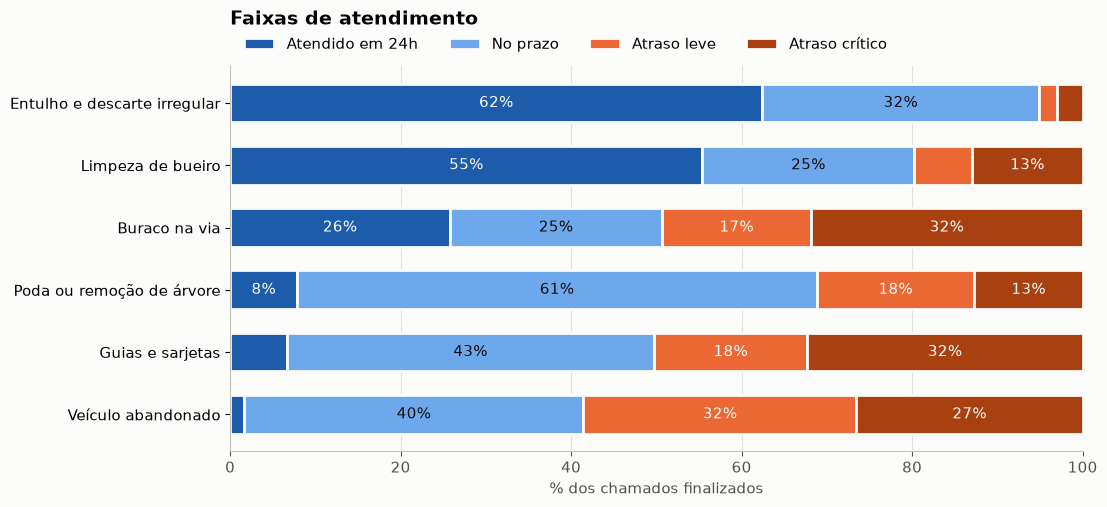

In [13]:
tab = (pd.crosstab(fin['servico'], fin['faixa_atendimento'], normalize='index') * 100).reindex(ordem)
fig, ax = plt.subplots(figsize=(11, 5))
esq = np.zeros(len(tab))
for nome, cor in FAIXAS:
    v = tab.get(nome, pd.Series(0, index=tab.index)).to_numpy()
    ax.barh(range(len(tab)), v, left=esq, color=cor, height=.62, label=nome, edgecolor=COR['fundo'], linewidth=2)
    for i, (x, w) in enumerate(zip(esq, v)):
        if w >= 7:
            ax.text(x + w / 2, i, f'{w:.0f}%', ha='center', va='center', color='white' if cor != '#6da7ec' else COR['texto'])
    esq += v
ax.set_yticks(range(len(tab)), tab.index); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel('% dos chamados finalizados'); ax.grid(axis='y', visible=False)
ax.legend(ncols=4, loc='lower left', bbox_to_anchor=(0, 1)); ax.set_title('Faixas de atendimento', pad=30)
plt.show()

**Leitura:** entulho e bueiro resolvem mais da metade em até 24h. Em buraco na via e guias e sarjetas,
cerca de **um terço termina em atraso crítico** (mais que o dobro do prazo).

### 6.3 Geografia das demandas

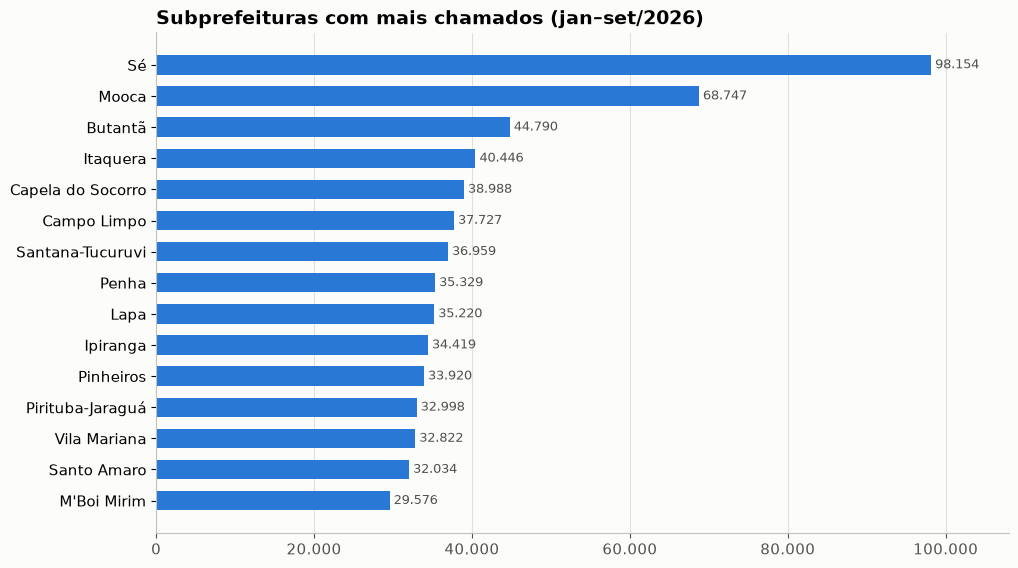

,finalizados,pct_no_prazo
prefeitura_operacional,,
Vila Mariana,7319,"60,36"
Butantã,11198,"63,36"
Lapa,6861,"65,15"
Capela do Socorro,14520,"83,46"
Casa Verde-Limão-Cachoeirinha,7572,"84,80"
Jabaquara,6721,"86,68"


In [14]:
base = limpo[limpo['status'] != 'cancelada']
vol = base['prefeitura_operacional'].value_counts().head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(vol.index, vol.to_numpy(), color=COR['serie'], height=.62)
for i, v in enumerate(vol.to_numpy()):
    ax.text(v, i, ' ' + br(f'{v:,.0f}'), va='center', fontsize=9.5, color=COR['texto2'])
ax.xaxis.set_major_formatter(MILHAR); ax.grid(axis='y', visible=False); ax.margins(x=.1)
ax.set_title('Subprefeituras com mais chamados (jan–set/2026)')
plt.show()

prazo_pref = fin.groupby('prefeitura_operacional').agg(finalizados=('flag_cumpriu_sla', 'size'),
                                                       pct_no_prazo=('flag_cumpriu_sla', 'mean'))
prazo_pref = prazo_pref[prazo_pref['finalizados'] >= 300].assign(pct_no_prazo=lambda d: 100 * d['pct_no_prazo'])
prazo_pref.sort_values('pct_no_prazo').iloc[[0, 1, 2, -3, -2, -1]]

**Leitura:** a Sé concentra o maior volume. No cumprimento de prazo há **mais de 25 pontos de diferença**
entre a melhor e a pior subprefeitura — um sinal para a gestão olhar onde a operação trava.

### 6.4 Sazonalidade e tendência

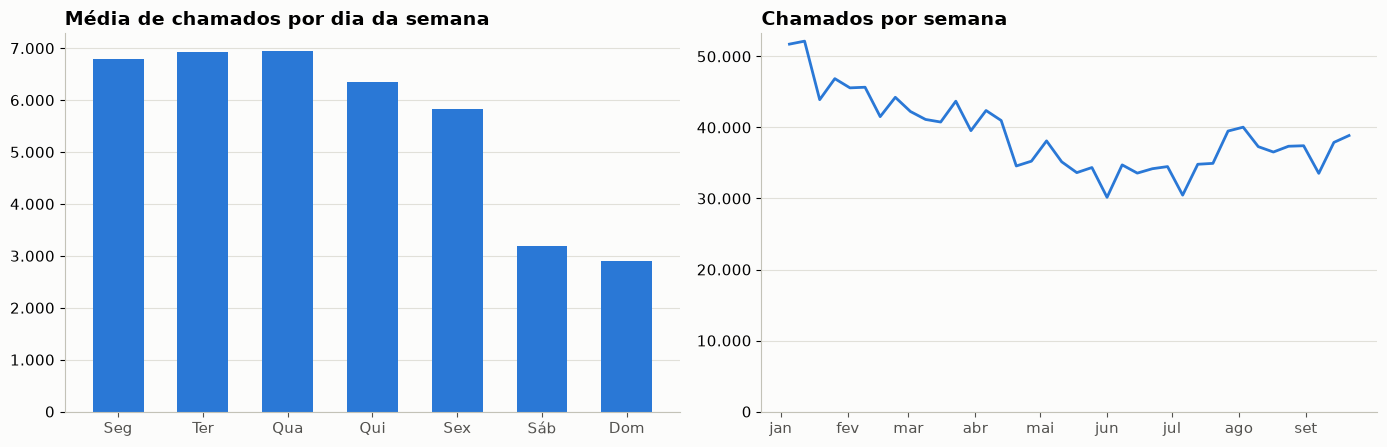

Fim de semana: 15,6% dos chamados


In [15]:
DIAS = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
media_dia = base.groupby('dia_semana').size() / base.groupby('dia_semana')['data_abertura'].nunique()
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
axs[0].bar(DIAS, media_dia.reindex(range(7)).to_numpy(), color=COR['serie'], width=.6)
axs[0].yaxis.set_major_formatter(MILHAR); axs[0].grid(axis='x', visible=False)
axs[0].set_title('Média de chamados por dia da semana')

semanal = base.set_index('data_abertura').resample('W-MON', label='left', closed='left').size().iloc[1:-1]
axs[1].plot(semanal.index, semanal.to_numpy(), color=COR['serie'], lw=2)
meses = pd.date_range(semanal.index.min().replace(day=1), semanal.index.max(), freq='MS')
axs[1].set_xticks(meses, ['jan', 'fev', 'mar', 'abr', 'mai', 'jun', 'jul', 'ago', 'set', 'out'][:len(meses)])
axs[1].yaxis.set_major_formatter(MILHAR); axs[1].set_ylim(bottom=0); axs[1].grid(axis='x', visible=False)
axs[1].set_title('Chamados por semana')
plt.tight_layout(); plt.show()
print(f"Fim de semana: {100 * base['flag_fim_de_semana'].mean():.1f}% dos chamados".replace('.', ','))

**Leitura:** o volume cai pela metade no fim de semana e segue o calendário: pico em janeiro,
vale no inverno (jun–jul) e retomada em agosto. A base não traz hora de abertura, então não há análise por hora.

### 6.5 Canais de abertura

In [16]:
canal = (100 * base['canal'].fillna('(vazio)').value_counts(normalize=True))
display(canal.rename('% da base').to_frame())
(pd.crosstab(sla['servico'], sla['canal'], normalize='index') * 100).round(1)

,% da base
canal,
PORTAL,"48,75"
CRM,"32,05"
MOBILE,"12,75"
INTEGRACAO,"3,35"
CHATBOT,"3,09"
RESOLUCAO,"0,01"


canal,CHATBOT,CRM,MOBILE,PORTAL,RESOLUCAO
servico,,,,,
Buraco na via,"2,90","18,30","52,50","26,20","0,00"
Entulho e descarte irregular,"9,80","28,20","40,60","21,40","0,00"
Guias e sarjetas,"5,40","25,10","35,50","34,00","0,00"
Limpeza de bueiro,"9,50","39,00","28,00","23,50","0,00"
Poda ou remoção de árvore,"6,10","33,70","16,80","43,40","0,00"
Veículo abandonado,"9,00","25,50","31,40","34,10","0,00"


**Leitura:** na base toda o **Portal** lidera, mas **nos serviços com local o celular (Mobile) é o canal
principal** — mais de 50% dos buracos. Isso reforça um app com mapa e geolocalização, como o Cidade Alfa 156+.

### 6.6 O mesmo problema registrado várias vezes

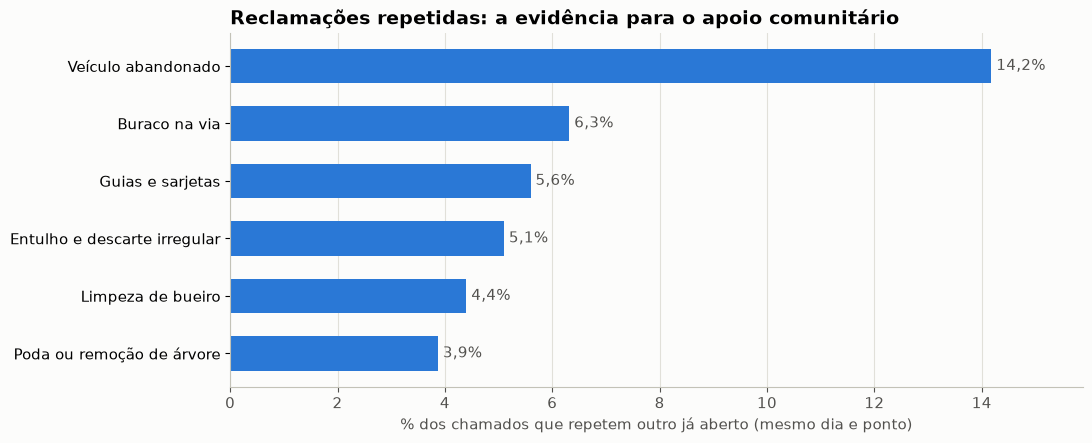

In [17]:
app = limpo[limpo['servico_app'].notna()]
dup = (100 * app.groupby(app['servico_app'].map(lambda k: SERVICOS[k]['nome']))['flag_duplicata_provavel'].mean()).sort_values()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.barh(dup.index, dup.to_numpy(), color=COR['serie'], height=.6)
for i, v in enumerate(dup.to_numpy()):
    ax.text(v, i, ' ' + br(f'{v:.1f}%'), va='center', color=COR['texto2'])
ax.set_xlabel('% dos chamados que repetem outro já aberto (mesmo dia e ponto)')
ax.grid(axis='y', visible=False); ax.margins(x=.12)
ax.set_title('Reclamações repetidas: a evidência para o apoio comunitário')
plt.show()

**Leitura:** 14% dos chamados de veículo abandonado repetem um já aberto. É a evidência quantitativa para o
**apoio comunitário (RN-03)**: em vez de abrir outro chamado, o cidadão apoia o existente — menos retrabalho
para a prefeitura e um sinal claro de prioridade.

## Passo 7 — Exportar as bases preparadas

As bases seguem o padrão medalhão da arquitetura da Fase 3 e alimentam os painéis da Fase 5.

In [18]:
Path('saida').mkdir(exist_ok=True)
limpo.drop(columns=['status_original']).to_parquet('saida/sp156_limpo.parquet', index=False)
sla.drop(columns=['status_original']).to_parquet('saida/sp156_sla_atributos.parquet', index=False)
tempo.to_csv('saida/eda_tempo_por_servico.csv')
print('Arquivos em ./saida:', sorted(p.name for p in Path('saida').iterdir()))
# No Colab, para baixar: from google.colab import files; files.download('saida/sp156_sla_atributos.parquet')

Arquivos em ./saida: ['eda_tempo_por_servico.csv', 'sp156_limpo.parquet', 'sp156_sla_atributos.parquet']


## Conclusões e ponte para a Fase 5

1. **Qualidade:** a base é rica, mas tem lacunas estruturais (sem protocolo, 37% sem local, nomes
   inconsistentes). Tratamos com *flags* e registramos cada decisão.
2. **SLA:** o desempenho varia muito por serviço — de 95% no prazo (entulho) a ~40% (veículo abandonado) — e
   entre subprefeituras.
3. **Distribuição:** tempos com cauda longa → painéis com **mediana e percentis**, não média simples.
4. **Canal:** nos serviços com local, o cidadão já usa o celular — o app com mapa encaixa no comportamento real.
5. **Comunidade:** reclamações repetidas mostram a demanda por **apoio comunitário** e alimentam o score de prioridade.

**Fase 5:** a base `sp156_sla_atributos` já traz os campos dos painéis — `flag_cumpriu_sla`,
`estouro_sla_dias`, `faixa_atendimento`, `score_prioridade_comunidade`, calendário e geografia.